# Fair Bin ablation

One knob at a time away from Fair Bin, as `robust_ablation.py` ran it. Fair Bin is the 5-fold out-of-fold
decision-stump tally, the Wilson bound at the Bonferroni z, and no size limits. Each arm uses k = 10, a
random-forest eval model and the 70/30 split, with bins chosen from the training rows only.

| Arm | Change |
|---|---|
| Fair Bin | — |
| min size 5% | every bin ≥ 5% of the training rows (floor lowered 5% a step when ties make it infeasible) |
| z = 0 | no Wilson bound: the DP minimises the raw error rate |
| G = 100 | values pooled into ≤ 100 equal-row groups before the DP (z from the group count) |
| M̂ = RF | out-of-fold tally from a random forest instead of the stump |
| M̂ = LR | out-of-fold tally from standardised logistic regression |

Records MRE and time (tally + DP) per dataset and seed, then draws `figures/ablation_mre.png` and
`figures/ablation_time.png`. **Run time:** about an hour on all 15 datasets, mostly KDD. Set `DATASETS`
to a subset to try it.

In [1]:
import sys
from pathlib import Path
from time import perf_counter
import warnings

import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import datasets, fairbin, figures, metrics

DATASETS = datasets.group_names("uci")      # the 15 UCI datasets
SEEDS = [92, 50, 61, 19, 11, 8, 2, 51, 70,1]  # the paper's ten eval seeds
K = 10
MODEL = "rf"
ARMS = ["original", "minsize_5pct", "z0", "pregroup_G100", "proxy_rf", "proxy_lr"]

## The other tally models
`proxy_learner.PROXIES` / `proxy_learner.oof_predictions`, copied: the same folds as Fair Bin's stump, another model.

In [2]:
PROXIES = {
    "rf": lambda seed: RandomForestClassifier(random_state=seed, n_jobs=-1),
    "lr": lambda seed: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
}


def oof_predictions(train, y_name, seed, proxy, folds=fairbin.FOLDS):
    X = train.drop(columns=[y_name])
    y = train[y_name].to_numpy()
    splitter = StratifiedKFold if pd.Series(y).value_counts().min() >= folds else KFold
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # lr convergence on unscaled-looking folds
        return cross_val_predict(PROXIES[proxy](seed), X, y,
                                 cv=splitter(n_splits=folds, shuffle=True, random_state=seed))

## Cuts per arm

In [3]:
def arm_cuts(arm, values, errors, rows):
    """(cuts, z, relaxation steps) for one arm from the per-value counts."""
    if arm == "pregroup_G100":  # pooled even below 100 values: any value under 1/100 of the rows joins a neighbour
        g_values, g_errors, _, g_rows = fairbin.pregroup(values, errors, rows, rows, 100)
        z = fairbin.bonferroni_z(len(g_values))
        cuts = fairbin.choose_cuts(g_values, g_errors, g_rows, K, z)[1]
        cuts[-1] = float(values[-1])
        return cuts, z, 0
    z = 0.0 if arm == "z0" else fairbin.bonferroni_z(len(values))
    if arm == "minsize_5pct":
        _, cuts, _, steps = fairbin.choose_cuts_bounded(values, errors, rows, K, z, min_share=0.05)
        return cuts, z, steps
    return fairbin.choose_cuts(values, errors, rows, K, z)[1], z, 0

## Run
One tally per (dataset, seed, tally model), shared by the arms that use it; each arm is charged that tally's time plus its own DP time.

In [4]:
out = []
start = perf_counter()
for ds in DATASETS:
    data, spec, n_classes = datasets.load(ds)
    col, target = spec.bin_col, spec.target
    for seed in SEEDS:
        train_x, _, _, _ = metrics.split(data, target, seed)
        train = data.loc[train_x.index]
        tallies = {}
        for arm in ARMS:
            proxy = arm[len("proxy_"):] if arm.startswith("proxy_") else "stump"
            if proxy not in tallies:
                t0 = perf_counter()
                pred = (fairbin.oof_predictions(train.drop(columns=[target]), train[target], seed) if proxy == "stump"
                        else oof_predictions(train, target, seed, proxy))
                tallies[proxy] = (fairbin.error_counts(train[col], train[target], pred), perf_counter() - t0)
            counts, tally_time = tallies[proxy]
            t1 = perf_counter()
            cuts, z, steps = arm_cuts(arm, *counts)
            dp_time = perf_counter() - t1
            binned = fairbin.apply_bins(data[col], cuts).to_numpy(float)
            bin_idx, layout = metrics.bin_layout(binned, cuts)
            ev = metrics.evaluate(data, col, target, binned, bin_idx, len(cuts) - 1, MODEL, seed, n_classes == 2)
            out.append(dict(dataset=ds, label=arm, eval_seed=seed, proxy=proxy, z=z, relax_steps=steps,
                            mre=ev["mre"], accuracy=ev["accuracy"], smallest_bin_share=layout["smallest_bin_share"],
                            tally_time_s=tally_time, dp_time_s=dp_time, bin_cuts=cuts))
    print(f"[{(perf_counter() - start) / 60:5.1f}m] {ds} done", flush=True)
runs = pd.DataFrame(out)

[  0.7m] uci863_maternal done
[  1.1m] uci503_hcv done
[  1.3m] uci30_contraceptive done
[  2.2m] uci579_myocardial done
[  2.6m] uci544_obesity done
[  2.9m] uci890_aids done
[  3.1m] uci887_nhanes done
[  3.6m] uci272_skillcraft done
[  6.1m] uci697_dropout done
[  6.7m] uci852_gendergap done
[  9.7m] uci350_credit done
[ 13.5m] uci222_bank done
[ 19.2m] uci2_adult done
[ 20.4m] uci827_sepsis done
[ 45.5m] uci117_kdd done


## Summary
Per dataset: mean MRE and accuracy over seeds, median tally and DP time. Then per arm: averages over datasets, and how many datasets each arm beats or loses to Fair Bin on (mean paired difference over seeds beyond ±2 SE).

In [5]:
summary = runs.groupby(["dataset", "label"]).agg(
    mre=("mre", "mean"), accuracy=("accuracy", "mean"),
    tally_time_s=("tally_time_s", "median"), dp_time_s=("dp_time_s", "median")).reset_index()

wide = runs.pivot_table(index=["dataset", "eval_seed"], columns="label", values="mre")
verdict = {}
for arm in ARMS[1:]:
    v = {"better": 0, "tie": 0, "worse": 0}
    for _, d in wide.groupby(level="dataset"):
        diff = (d[arm] - d["original"]).dropna()
        if len(diff) < 3:
            continue
        m, se = diff.mean(), diff.std(ddof=1) / np.sqrt(len(diff))
        v["better" if m + 2 * se < 0 else "worse" if m - 2 * se > 0 else "tie"] += 1
    verdict[arm] = v

table = summary.groupby("label").agg(mean_mre=("mre", "mean"), mean_accuracy=("accuracy", "mean"),
                                     median_time_s=("tally_time_s", lambda t: np.nan)).reindex(ARMS)
table["median_time_s"] = (summary.assign(t=summary.tally_time_s + summary.dp_time_s)
                          .groupby("label").t.median().reindex(ARMS))
table = table.join(pd.DataFrame(verdict).T)
table.index = [figures.ABL_NAMES[a] for a in table.index]
table.round(4)

,mean_mre,mean_accuracy,median_time_s,better,tie,worse
Fair Bin,0.3061,0.7568,0.0580,NaN,NaN,NaN
min size 5%,0.3129,0.7583,0.0580,1.0,8.0,6.0
z = 0,0.4433,0.7553,0.0580,2.0,7.0,6.0
G = 100,0.3082,0.7567,0.0412,1.0,11.0,3.0
$\hat{\mathcal{M}}$ = RF,0.3037,0.7571,1.0113,1.0,11.0,3.0
$\hat{\mathcal{M}}$ = LR,0.3073,0.7576,0.3332,0.0,12.0,3.0


## Figures

wrote /Users/samika/BinStability/repo/figures/ablation_mre.png


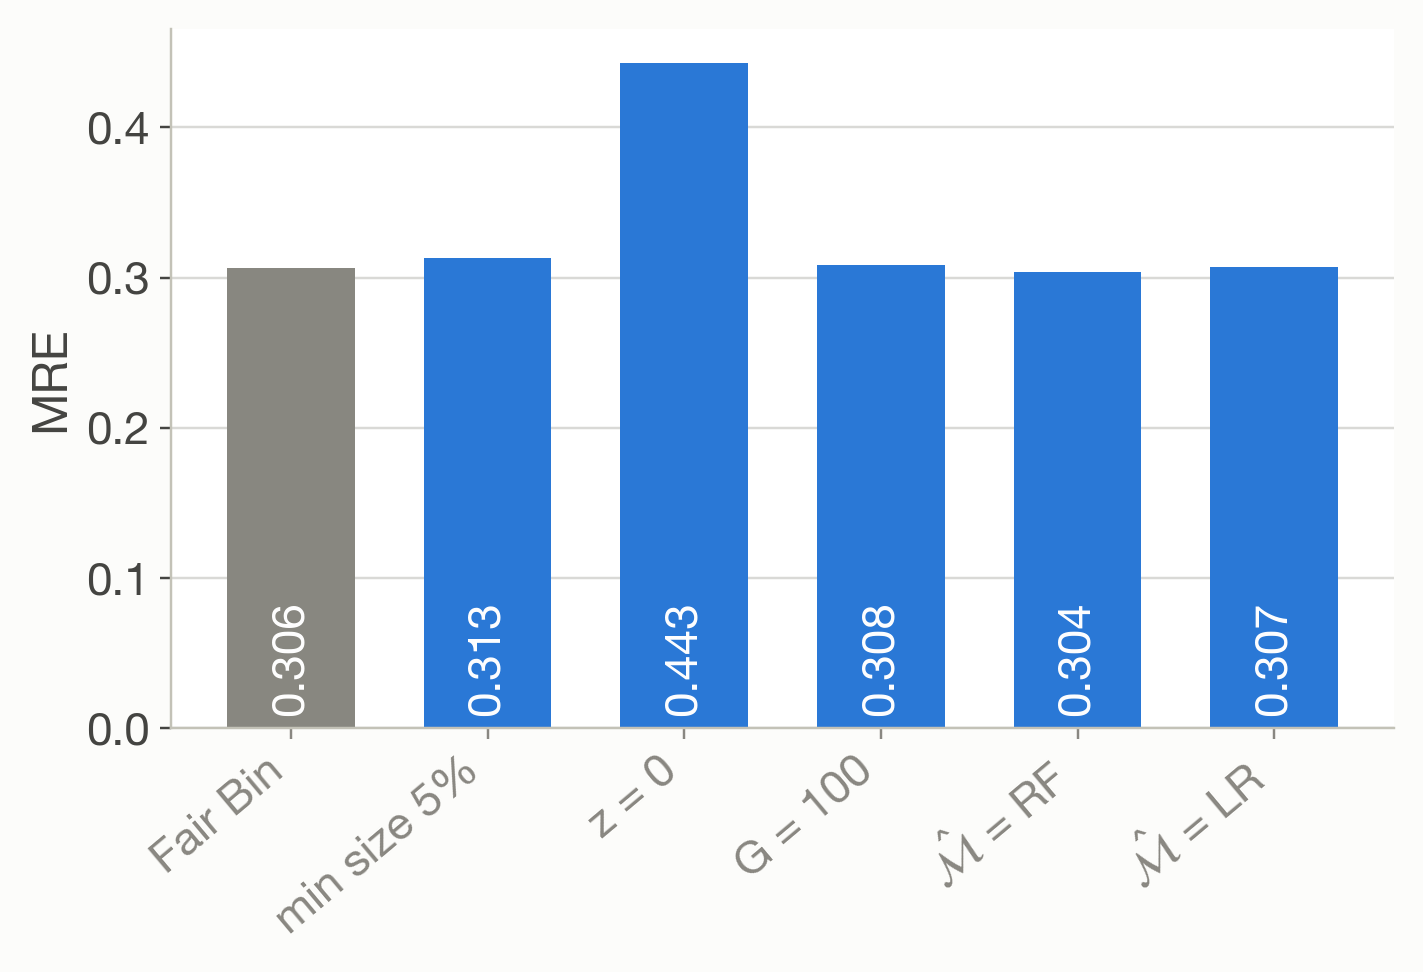

wrote /Users/samika/BinStability/repo/figures/ablation_time.png


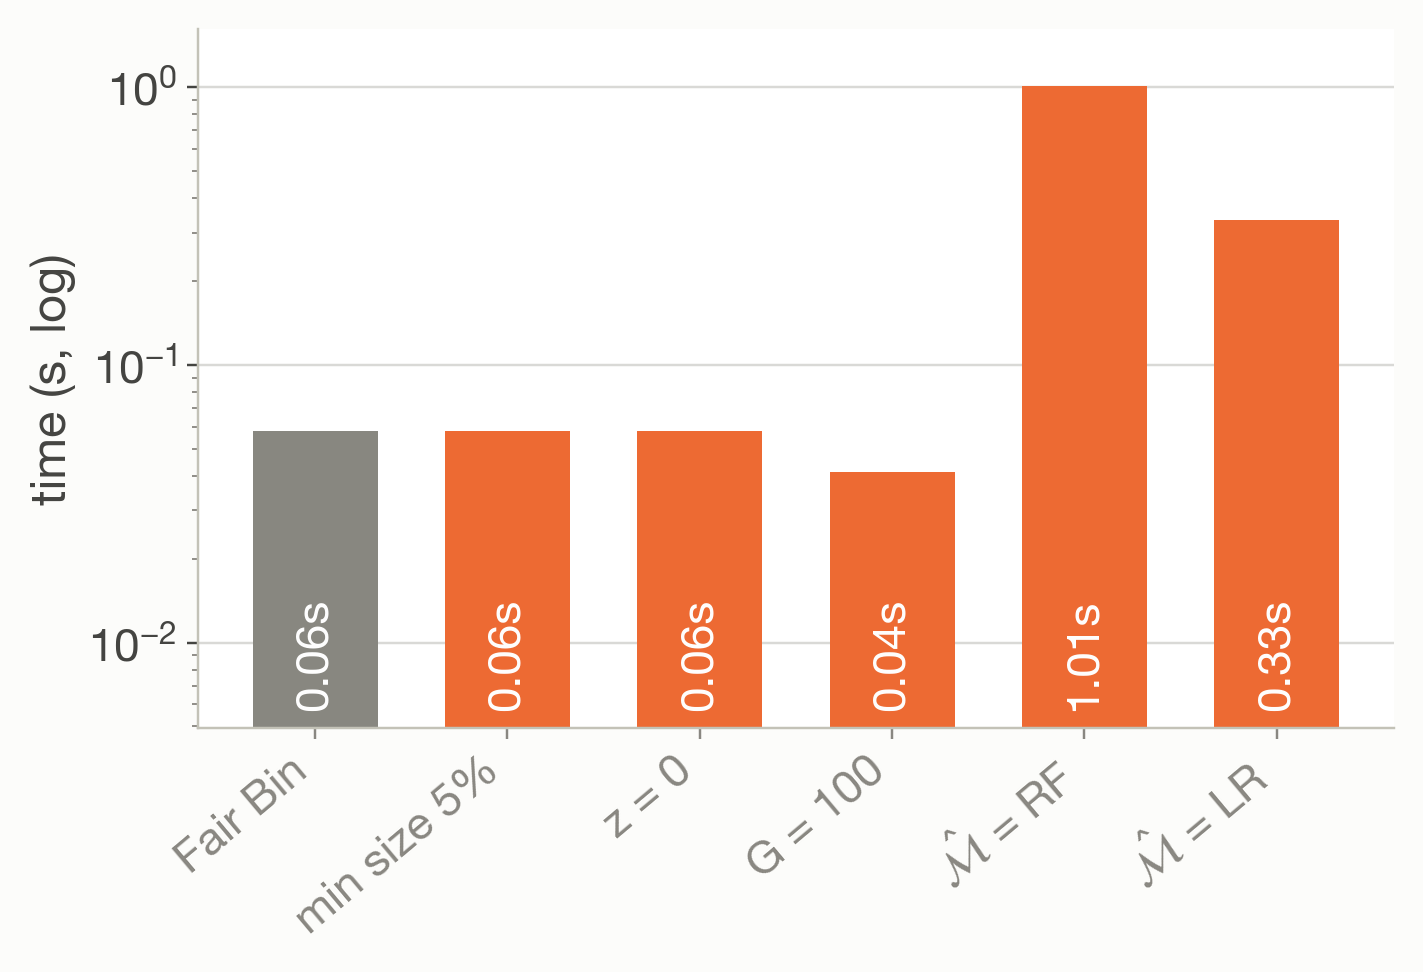

In [6]:
(ROOT / "figures").mkdir(exist_ok=True)
for kind in ("mre", "time"):
    path = ROOT / "figures" / f"ablation_{kind}.png"
    figures.draw_ablation(summary, path, kind)
    display(Image(str(path)))